# Exposición al incumplimiento y factor de conversión de crédito: la trampa de la terminología

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** el cuaderno 01 de este tema (la LGD de recuperación) y los cuadernos 01 y 02 del tema 01
- **Tiempo de lectura:** unos 35 minutos

## Objetivos

Al terminar este cuaderno puedes:

- calcular la exposición al incumplimiento de una línea rotativa a partir de un factor de conversión de crédito, y volver de la EAD al factor;
- decir cuál de los tres números llamados "el CCF" quiere decir un documento: el factor europeo sobre el monto no utilizado, el equivalente de préstamo de EE.UU. y las razones de Qi (2009) al saldo y al límite;
- elegir y leer los tres diseños de fecha de referencia (horizonte fijo, cohorte, horizonte variable) con `reference_indices` y `ccf_observations`, y decir cuándo un factor no está definido;
- tratar un factor bajo 0 o sobre 1 de las cuatro formas de `treat_ccf`, y decir qué hace cada una a la media;
- leer la distribución de los factores del generador C09 y la regla del monto no utilizado pequeño.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.lgd_ead import ccf, workout

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 0.9.0
numpy 2.4.6
matplotlib 3.11.2


## Datos

Dos artefactos versionados del caso C09, la exposición al incumplimiento y el factor de conversión de líneas rotativas: `data/derived/C09/level-0.json` (la variante del nivel de aceleración 0) y `data/derived/C09/models-generator.json` (el generador y los diseños detrás de cada nivel). C09 tiene **una verdad conocida**. Sus líneas las produce un generador cuya estructura de campos y distribuciones marginales siguen las carteras hipotéticas de tarjetas de 2025 de la Reserva Federal, y el generador simula los saldos con un factor de conversión que es un parámetro propio. Por eso cada estimación se muestra junto a la verdad que debe recuperar, y los datos son sintéticos, no observaciones de ningún prestamista (el artefacto lo dice en `outputs.generator.notice`).

El nivel 0 significa sin aceleración: el monto no utilizado se usa a ritmo constante en los doce meses previos al incumplimiento. Los cuadernos 05 y 07 de este tema suben el nivel; aquí usamos el nivel 0 para aprender el vocabulario. Como C08, los artefactos fueron horneados con un motor anterior al instalado, y la celda siguiente imprime ambas versiones.

In [2]:
# Abrir los dos artefactos, imprimir el aviso del generador, el CCF conocido, la convención y los diseños
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived" / "C09"
level0 = json.loads((DERIVED / "level-0.json").read_text(encoding="utf-8"))
gen = json.loads((DERIVED / "models-generator.json").read_text(encoding="utf-8"))
out = level0["outputs"]
print("caso:", level0["case_id"], "| variante:", level0["variant_id"], "| estado de la verdad:", "sintética, verdad conocida")
print("horneado con riskvalidation:", level0["provenance"]["riskvalidation_version"], "| instalado:", rv.__version__)
print()
print(out["generator"]["notice"]["es"])
print()
print("CCF conocido del nivel 0:", out["generator"]["true_ccf"]["value"])
print("convención:", out["convention"]["name"], "|", out["convention"]["formula"])
print(out["convention"]["definition"]["es"])
print(out["convention"]["us_terms"]["es"])
for design in gen["fit"]["designs"]:
    print("-", design["label"]["es"])

caso: C09 | variante: level-0 | estado de la verdad: sintética, verdad conocida
horneado con riskvalidation: 0.6.0 | instalado: 0.9.0

Datos sintéticos: son líneas de crédito rotativas generadas, no observaciones de ninguna cartera ni evidencia sobre ningún banco o emisor de tarjetas. Su estructura de campos y sus marginales siguen las carteras hipotéticas de tarjetas de 2025 de la Reserva Federal; el CCF con que cada nivel simula los saldos es un parámetro del propio generador, de modo que cada estimación se muestra junto a la verdad que debe recuperar. Montos en USD.

CCF conocido del nivel 0: 0.6
convención: eu-undrawn | CCF = (EAD - E(t_r)) / (L(t_r) - E(t_r))
CCF = (EAD - utilizado en la fecha de referencia) / (límite - utilizado en la fecha de referencia): la parte del monto no utilizado que se usa al incumplir.
La misma razón es el equivalente de crédito (LEQ) en términos de EE.UU.; Qi (2009) llama CCF a EAD sobre el saldo y EADF a EAD sobre el límite.
- Horizonte fijo: 12 meses

## Método

### Paso 1: una línea, tres números

Una línea rotativa tiene un límite $L$ y un saldo utilizado $E$ en una fecha de referencia, y la exposición al incumplimiento del banco es la $EAD$. La investigación de este producto registra la convención europea como

$$CCF = \frac{EAD - E(t_r)}{L(t_r) - E(t_r)} \qquad\Longleftrightarrow\qquad EAD = E(t_r) + CCF\,\big(L(t_r) - E(t_r)\big)$$

con $t_r$ la fecha de referencia anterior a la fecha de incumplimiento $t_d$: la parte del monto no utilizado que se usa al incumplir. En términos de EE.UU. la misma razón es el equivalente de préstamo (LEQ). Qi (2009) usa las mismas palabras para otras razones: su "CCF" es $EAD / E$ (sobre el saldo) y su "EADF" es $EAD / L$ (sobre el límite). (Fuentes: el docstring de `riskvalidation.lgd_ead.ccf` en la versión 0.8.1, y Qi 2009, OCC Economics Working Paper 2009-2, como se nombra allí.) Un documento que dice "el CCF" sin nombrar el denominador puede querer decir cualquiera de los tres, y esta es la trampa de la terminología.

`to_us_terms(drawn, limit, ead)` devuelve los tres números de cada línea, y `ead_from_ccf(drawn, limit, ccf)` vuelve atrás. La celda siguiente inventa tres líneas: una parcialmente usada al incumplir, una totalmente usada y una sobre su límite.

In [3]:
# Tres líneas inventadas: los tres números llamados CCF, y la EAD recuperada desde el factor europeo
names = ["parcialmente usada", "totalmente usada", "sobre el límite"]
drawn = np.array([60.0, 20.0, 90.0])
limit = np.array([100.0, 100.0, 100.0])
ead = np.array([85.0, 100.0, 120.0])

leq, ccf_us, eadf = ccf.to_us_terms(drawn, limit, ead)
print(f"{'':20s} {'E':>5s} {'L':>5s} {'EAD':>5s} | {'factor europeo (EAD-E)/(L-E)':>46s} | {'EAD/E':>7s} | {'EAD/L':>7s}")
for i, name in enumerate(names):
    print(f"{name:20s} {drawn[i]:5.0f} {limit[i]:5.0f} {ead[i]:5.0f} | {leq[i]:46.4f} | {ccf_us[i]:7.4f} | {eadf[i]:7.4f}")
print("EAD recuperada desde el factor europeo:", ccf.ead_from_ccf(drawn, limit, leq))

                         E     L   EAD |                   factor europeo (EAD-E)/(L-E) |   EAD/E |   EAD/L
parcialmente usada      60   100    85 |                                         0.6250 |  1.4167 |  0.8500
totalmente usada        20   100   100 |                                         1.0000 |  5.0000 |  1.0000
sobre el límite         90   100   120 |                                         3.0000 |  1.3333 |  1.2000
EAD recuperada desde el factor europeo: [ 85. 100. 120.]


La misma línea vale 0.625, 1.4167 y 0.85 según la razón. El factor europeo es exactamente 1 para la línea totalmente usada (usó todo su monto no utilizado) y 3 para la línea sobre su límite (el límite era 100, el saldo 90, y el banco terminó 30 sobre el saldo: tres veces los 10 que quedaban sin usar). Nótese lo que hace el factor cuando el monto no utilizado es pequeño: unas pocas unidades monetarias sin utilizar en el denominador hacen explotar la razón, y por eso el paso 5 vuelve sobre esto.

### Paso 2: ¿qué mes es la fecha de referencia?

El factor necesita una fecha de referencia $t_r$ anterior al incumplimiento, y la elección es un diseño del modelo, no un detalle. `reference_indices(design, default_index, ...)` del motor da los meses de la trayectoria de una línea para cada diseño:

- `fixed-horizon`: una fecha, `horizon` meses antes del incumplimiento (`t_d - h`);
- `cohort`: una fecha, el inicio de la cohorte calendario que contiene el incumplimiento (quien llama entrega `cohort_start_index`);
- `variable-horizon`: `n_reference` fechas, `t_d - h + k * step` para `k = 0 ... n_reference - 1`.

(Fuente: el docstring de `reference_indices`; los tres diseños siguen a Moral (2006) como los resume la investigación, y el motor marca el detalle NO VERIFICADO porque ese capítulo no se leyó.) Una fecha de referencia negativa o no anterior al incumplimiento produce un error. `ccf_observations(drawn, limit, ead, reference_index)` devuelve entonces el factor y el monto no utilizado en cada fecha, y `aggregate_ccf` los combina como la media de los factores o como la razón agrupada $\sum (CCF\,U) / \sum U$ de los montos no utilizados $U$.

La celda siguiente inventa la trayectoria mensual de una línea que cae en incumplimiento en el mes 20 con una EAD de 88, y de una segunda línea totalmente usada desde el mes 14. Imprime los meses que elige cada diseño y el factor que da cada uno.

In [4]:
# Dos trayectorias mensuales inventadas, los meses de referencia de cada diseño, los factores y sus dos agregaciones
months = np.arange(21)
limit_path = np.full(21, 100.0)
drawn_a = np.linspace(30.0, 85.0, 21)
drawn_b = np.minimum(np.linspace(40.0, 130.0, 21), 100.0)
default_month = 20
DESIGN_NAME = {"fixed-horizon": "horizonte fijo", "cohort": "cohorte", "variable-horizon": "horizonte variable"}
designs = {
    "fixed-horizon": dict(horizon=12),
    "cohort": dict(cohort_start_index=12),
    "variable-horizon": dict(horizon=12, n_reference=4, step=3),
}
for label, path, final_ead in (("línea 1, EAD 88", drawn_a, 88.0), ("línea 2 (totalmente usada desde el mes 14), EAD 100", drawn_b, 100.0)):
    print(label)
    for design, kwargs in designs.items():
        idx = ccf.reference_indices(design, default_month, **kwargs)
        factors, undrawn = ccf.ccf_observations(path, limit_path, final_ead, idx)
        line = f"  {DESIGN_NAME[design]:19s} meses {idx.tolist()} factores {np.round(factors, 4).tolist()} no utilizado {np.round(undrawn, 2).tolist()}"
        if np.isfinite(factors).any():
            line += f" | media {ccf.aggregate_ccf(factors, undrawn, 'mean'):.4f} agrupado {ccf.aggregate_ccf(factors, undrawn, 'pooled'):.4f}"
        print(line)

línea 1, EAD 88
  horizonte fijo      meses [8] factores [0.75] no utilizado [48.0] | media 0.7500 agrupado 0.7500
  cohorte             meses [12] factores [0.6757] no utilizado [37.0] | media 0.6757 agrupado 0.6757
  horizonte variable  meses [8, 11, 14, 17] factores [0.75, 0.6981, 0.619, 0.4839] no utilizado [48.0, 39.75, 31.5, 23.25] | media 0.6378 agrupado 0.6632
línea 2 (totalmente usada desde el mes 14), EAD 100
  horizonte fijo      meses [8] factores [1.0] no utilizado [24.0] | media 1.0000 agrupado 1.0000
  cohorte             meses [12] factores [1.0] no utilizado [6.0] | media 1.0000 agrupado 1.0000
  horizonte variable  meses [8, 11, 14, 17] factores [1.0, 1.0, nan, nan] no utilizado [24.0, 10.5, 0.0, 0.0] | media 1.0000 agrupado 1.0000


Dos cosas para leer en la salida. Primero, la línea 1 da un factor distinto en cada diseño: 0.75 en el horizonte fijo, 0.6757 en el inicio de la cohorte, y 0.6378 (media) o 0.6632 (agrupado) en el horizonte variable. En esta trayectoria inventada el saldo sigue creciendo hacia el incumplimiento, así que una fecha de referencia más tardía deja menos monto no utilizado y la misma EAD es una parte menor de él. El factor es una propiedad del diseño tanto como de la línea, y C09 mide eso sobre una verdad conocida en el cuaderno 05. Segundo, para la segunda línea los meses en que el saldo ya llegó al límite dan `nan`: cuando el monto no utilizado no es positivo el factor no está definido, y el motor lo dice con un valor faltante, nunca con 0 o 1. Un incumplidor cuyos meses de referencia están todos totalmente usados simplemente no tiene factor, y C09 cuenta a esos incumplidores.

### Paso 3: un factor bajo 0 o sobre 1

Un factor bajo 0 significa que el saldo bajó entre la fecha de referencia y el incumplimiento; sobre 1, que el banco terminó sobre el límite. Ambos ocurren. `treat_ccf(ccf, treatment)` ofrece cuatro tratamientos e informa lo que hizo:

- `none`: conservar todos los valores (marcarlos con `range_flag`);
- `censor`: descartar las observaciones fuera de [0, 1];
- `floor-cap`: recortar a [0, 1], lo que el motor documenta como sesgo de la EAD;
- `bounded-scale`: devolver los valores recortados como respuesta de un logit fraccional.

Los factores faltantes se descartan primero y se cuentan, y los conteos de valores bajo 0 y sobre 1 se toman sobre la entrada cualquiera sea el tratamiento. La celda siguiente aplica los cuatro tratamientos a ocho factores inventados.

In [5]:
# Marcar ocho factores inventados y aplicar los cuatro tratamientos de treat_ccf
factors = np.array([-0.40, 0.10, 0.35, 0.60, 0.80, 1.00, 1.70, np.nan])
WORDS = {"below-zero": "bajo 0", "in-range": "en [0, 1]", "above-one": "sobre 1"}
print("range_flag:", [WORDS[f] for f in workout.range_flag(np.nan_to_num(factors, nan=0.5))])
LABELS = {"none": "ninguno", "censor": "censurar", "floor-cap": "piso y tope", "bounded-scale": "escala acotada"}
for treatment in ccf.TREATMENTS:
    treated = ccf.treat_ccf(factors, treatment)
    print(f"{LABELS[treatment]:16s} conservados {treated.values.size} descartados {treated.n_dropped} bajo 0 {treated.n_below_zero} sobre 1 {treated.n_above_one} factor medio {treated.values.mean():.4f}")

range_flag: ['bajo 0', 'en [0, 1]', 'en [0, 1]', 'en [0, 1]', 'en [0, 1]', 'en [0, 1]', 'sobre 1', 'en [0, 1]']
ninguno          conservados 7 descartados 1 bajo 0 1 sobre 1 1 factor medio 0.5929
censurar         conservados 5 descartados 3 bajo 0 1 sobre 1 1 factor medio 0.5700
piso y tope      conservados 7 descartados 1 bajo 0 1 sobre 1 1 factor medio 0.5500
escala acotada   conservados 7 descartados 1 bajo 0 1 sobre 1 1 factor medio 0.5500


### Paso 4: la distribución de los factores en C09

Ahora el generador versionado. El artefacto `level-0.json` guarda el histograma de los factores del diseño de horizonte fijo (`outputs.ccf_distribution`): los bordes de tramo, el conteo por tramo, y los conteos bajo 0 y sobre 1. La celda comprueba que los conteos suman, imprime las partes y dibuja el histograma con el CCF conocido marcado. El generador conoce la verdad (0.6 en el nivel 0), así que una línea vertical en ella muestra dónde deberían centrarse los factores.

diseño: horizonte fijo | incumplidores con factor definido: 30,154 | contados en los tramos: 30,154
bajo 0: 507 (1.68%) | sobre 1: 1,940 (6.43%)
CCF conocido: 0.6


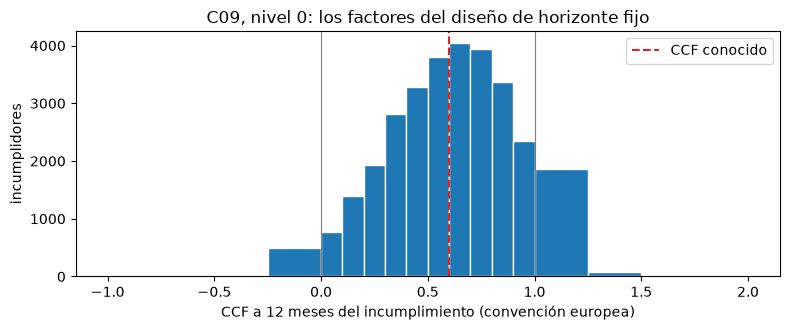

In [6]:
# Comprobar los conteos del histograma, imprimir las partes fuera de [0, 1] y dibujar la distribución con el CCF conocido
dist = out["ccf_distribution"]
edges = np.array(dist["edges"])
counts = np.array(dist["counts"])
print(f"diseño: {DESIGN_NAME[dist['design']]} | incumplidores con factor definido: {dist['n']:,} | contados en los tramos: {counts.sum():,}")
print(f"bajo 0: {dist['n_below_zero']:,} ({dist['n_below_zero'] / dist['n']:.2%}) | sobre 1: {dist['n_above_one']:,} ({dist['n_above_one'] / dist['n']:.2%})")
truth = out["generator"]["true_ccf"]["value"]
print("CCF conocido:", truth)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(edges[:-1], counts, width=np.diff(edges), align="edge", edgecolor="white", color="tab:blue")
ax.axvline(truth, color="tab:red", linestyle="--", label="CCF conocido")
ax.axvline(0.0, color="grey", linewidth=0.8)
ax.axvline(1.0, color="grey", linewidth=0.8)
ax.set_xlabel("CCF a 12 meses del incumplimiento (convención europea)")
ax.set_ylabel("incumplidores")
ax.set_title("C09, nivel 0: los factores del diseño de horizonte fijo")
ax.legend()
fig.tight_layout()
plt.show()

### Paso 5: cuando el monto no utilizado es pequeño

Si una línea tiene solo unas pocas unidades monetarias sin utilizar en la fecha de referencia, la razón $(EAD - E)/(L - E)$ divide por casi nada y es inestable. Qi (2009) cambia a otra razón bajo un umbral de monto no utilizado; `small_undrawn_rule(drawn, limit, ead, threshold)` devuelve qué líneas se cambian y la razón a usar: $EAD/L$ donde se cambia, el factor europeo en el resto. El umbral es un parámetro en la moneda de los montos. La celda siguiente inventa tres líneas, dos con menos de 50 sin utilizar, y luego imprime lo que el artefacto C09 registra sobre la regla: calcula el número de líneas que se cambiarían con un umbral de 50 USD y declara que la regla **no se aplica** en los factores horneados.

In [7]:
# Aplicar la regla del monto no utilizado pequeño a tres líneas inventadas y leer lo que el artefacto registra sobre ella
d = np.array([4_980.0, 4_000.0, 1_000.0])
lim = np.array([5_000.0, 4_030.0, 5_000.0])
e = np.array([5_020.0, 4_100.0, 3_000.0])
switched, ratio = ccf.small_undrawn_rule(d, lim, e, threshold=50.0)
for i in range(3):
    print(f"línea {i + 1}: no utilizado {lim[i] - d[i]:7.1f} cambiada {si_no(switched[i])!s:5s} razón usada {ratio[i]:.4f}")

small = out["small_undrawn"]
print(f"artefacto: umbral {small['threshold']} {small['currency']} | regla aplicada: {si_no(small['applied'])} | líneas que se cambiarían: {small['n_switched']:,} | referencia: {small['reference']}")

línea 1: no utilizado    20.0 cambiada sí    razón usada 1.0040
línea 2: no utilizado    30.0 cambiada sí    razón usada 1.0174
línea 3: no utilizado  4000.0 cambiada no    razón usada 0.5000
artefacto: umbral 50.0 USD | regla aplicada: no | líneas que se cambiarían: 8,903 | referencia: Qi (2009), OCC Economics Working Paper 2009-2


## Resultados

- **Una línea, tres números.** La línea parcialmente usada (saldo 60, límite 100, EAD 85) tiene un factor europeo de 0,6250, una razón al saldo de 1,4167 y una razón al límite de 0,8500. La línea totalmente usada tiene una razón al saldo de 5,0000 y la línea sobre su límite un factor europeo de 3,0000. `ead_from_ccf` devuelve las tres EAD inventadas (85, 100 y 120) desde los factores europeos, de modo que la identidad corre en ambos sentidos.
- **La fecha de referencia es un diseño.** Para la línea 1 el factor de horizonte fijo es 0,7500, el del inicio de la cohorte 0,6757 y el de horizonte variable 0,6378 como media y 0,6632 agrupado. Para la línea 2 los meses en que el saldo había llegado al límite dan un factor faltante, no un 0 ni un 1.
- **Tratar un factor fuera de [0, 1] cambia la media.** Sobre ocho factores inventados, conservar todos da 0,5929, censurar da 0,5700 (descarta tres observaciones: la bajo 0, la sobre 1 y la faltante) y poner piso y tope, o la escala acotada, da 0,5500.
- **C09 tiene factores fuera de [0, 1] y un centro conocido.** De 30.154 incumplidores con factor definido al horizonte de 12 meses, 507 (1,68%) están bajo 0 y 1.940 (6,43%) sobre 1, en torno a un CCF conocido de 0,6. La regla del monto no utilizado pequeño cambiaría 8.903 líneas con un umbral de 50 USD, y los factores horneados no la aplican.

Lo que el cuaderno no hace: no dice qué convención debe usar un regulador o un banco, solo qué significa cada una. Las tres líneas inventadas y las dos trayectorias existen para mostrar la aritmética y no traen información de ningún prestamista. El cuaderno siguiente vuelve a la LGD y ajusta la escalera de modelos sobre las cohortes de C08.

## Resumen

- El factor europeo es $(EAD - E)/(L - E)$, la parte del monto no utilizado usada al incumplir; Qi (2009) usa "CCF" para $EAD/E$ y "EADF" para $EAD/L$. `to_us_terms` devuelve los tres para que una página nunca los mezcle.
- La fecha de referencia es un diseño: `reference_indices` da los meses de los diseños de horizonte fijo, cohorte y horizonte variable, y `ccf_observations` devuelve un factor y un monto no utilizado en cada uno.
- Un factor no está definido (un valor faltante, nunca 0 o 1) cuando la línea está totalmente usada o sobre su límite en la fecha de referencia.
- Un factor fuera de [0, 1] es real; `treat_ccf` lo conserva, censura, recorta o acota, e informa los conteos.
- C09 es un generador con un CCF conocido, así que cada estimación de los cuadernos siguientes se juzga contra la verdad. La regla del monto no utilizado pequeño es un cambio parametrizado que los factores horneados no aplican.

**Qué probar a continuación.** Cambia el mes de incumplimiento o la trayectoria del paso 2 y mira cómo se mueve el factor con el diseño; luego sigue con el cuaderno 03, la escalera de modelos de LGD ajustados sobre las cohortes de C08.

## Referencias

- BCBS, Basel Framework, CRE32 (enfoque de calificaciones internas; los factores de conversión supervisores y el piso de EAD se aplican en el cuaderno 04). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- BCBS (2017), Basel III: Finalising post-crisis reforms (d424). https://www.bis.org/bcbs/publ/d424.htm
- Qi, M. (2009), Exposure at default of unsecured credit cards, OCC Economics Working Paper 2009-2: las razones al saldo y al límite, y el cambio bajo un monto no utilizado pequeño, como los nombra la documentación del motor de `riskvalidation.lgd_ead.ccf`.
- Moral, G. (2006), los tres diseños de fecha de referencia, como los resume la investigación de este producto y el docstring de `reference_indices` (el capítulo no se leyó: detalle NO VERIFICADO).
- Este repositorio: `docs/design/SDD.md` (caso C09, un generador con verdad conocida) y `data/derived/C09/level-0.json`.